# 05. 다운샘플링 실험 — 셀별 실행

스크립트(`05_sampling_*.py`)의 함수를 그대로 부른다. 코드 수정은 `.py` 에서 하고 여기선 실행·확인만.
긴 실험(여러 조건)은 노트북보다 터미널 `nohup` 이 안전하다 — 이 노트북은 **조건 1~2개를 돌려보며 결과를 눈으로 보는 용도**.

```
select → audit (통계) → train (조건별) → collect (합쳐서 비교)
```

실험 조건 = select(방식×비율) × apply(loss|struct) × reweight(ipw|none) × pi_eff × seed
- apply=loss : 그래프 유지, loss 에 넣는 정상 target 만 줄임 (지도 샘플링)
- apply=struct : adjacency 에서도 제거 (구조 샘플링)
- reweight=ipw : 선택 정상에 모집단/선택 가중치 (full 손실의 불편추정)  /  none : 가중치 1
- pi_eff : 손실에서 양성 가중치 비중. pos_weight 를 여기서 역산해 r 과 분리



- 1차  random × r{10,30,100} × reweight{none,ipw}        6조건   ← 비율·가중치 축
- 2차  1차 최적 r 에서 strata/hard/cssmc × none            3조건   ← 방식 축
- 3차  최적 (r, 방식) 에서 pi_eff{0.10,0.50}              2조건
- 4차  최적에서 struct                                      1조건
- 5차  상위 2~3개 시드 43,44                               4~6조건

단계	할일
- 1차	그냥 실행
- 2차	R 수정 → select 셀 2차 블록 주석 해제 → GRID 2차 블록 주석 해제 → 설정 셀부터 다시 실행
- 3차	BEST 수정 → GRID 3차 블록 주석 해제 → 실행
- 4차	GRID 4차 블록 주석 해제
- 5차	GRID 5차 블록 주석 해제 (2위 조건도 넣고 싶으면 튜플 하나 추가)

## 0. 설정

In [1]:
!pip install --break-system-packages --no-cache-dir -q torch_geometric

In [2]:
import importlib, json, time, sys
from pathlib import Path
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

import sampling_lib as L
select  = importlib.import_module("05_sampling_select")
audit   = importlib.import_module("05_sampling_audit")
train   = importlib.import_module("05_sampling_train")
collect = importlib.import_module("05_sampling_collect")

THREADS, MEMORY = 8, "12GB"          # cgroup 한도 27GB — DuckDB 한도 + 파이썬 배열이 그 안에 들어야 함
TRAIN = "2022-08-08:2022-09-27"      # 학습 구간 (태훈님 분할)
VAL   = "2022-09-28:2022-10-14"      # 검증 구간

# 단계가 끝날 때마다 여기만 바꾼다 — 나머지 셀은 이 두 값으로 이름을 조합한다
R    = "10"                 # 1차(비율 축) 결과로 정한 정상:양성 비율
BEST = f"random_r{R}"       # 2차(방식 축) 결과로 정한 최적 select 이름 (예: f"strata_r{R}_day-amount-cross_bank", f"hard_r{R}")
print("ROOT", L.ROOT); print("BASE", L.BASE); print("출력", L.SAMPLING)
for f in ["transactions.parquet", "patterns.parquet", "features/edge_features.parquet", "features/node_features.parquet"]:
    print(f"{'OK ' if (L.BASE/f).is_file() else '없음'} {f}")

ROOT /workspace/money_laundry_ai_
BASE /workspace/money_laundry_ai_/parquets/HI-Large
출력 /workspace/money_laundry_ai_/parquets/HI-Large/sampling
OK  transactions.parquet
OK  patterns.parquet
OK  features/edge_features.parquet
OK  features/node_features.parquet


### 학습 구간 라벨 분포 — 일별 양성 수와 정상 수 (r 범위 정하는 근거)

In [3]:
con = L.connect(THREADS, MEMORY)
lab = L.load_labels(con, L.parse_window(TRAIN))
daily = lab.groupby("day").agg(pos=("y", "sum"), n=("y", "size"), unmatched=("in_pattern", lambda s: int(((lab.loc[s.index, "y"] == 1) & ~s).sum())))
daily["neg"] = daily.n - daily.pos; daily["neg_per_pos"] = (daily.neg / daily.pos).round(0)
print(f"학습 구간 {len(lab):,}건, 양성 {int(lab.y.sum()):,} (패턴 외 {int(daily.unmatched.sum()):,}), 정상 {int((lab.y==0).sum()):,}")
print(f"정상:양성 전체 = 1:{(lab.y==0).sum()/lab.y.sum():.0f}")
daily[["pos", "unmatched", "neg", "neg_per_pos"]].describe().round(0)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

학습 구간 91,432,129건, 양성 98,932 (패턴 외 43,095), 정상 91,333,197
정상:양성 전체 = 1:923


,pos,unmatched,neg,neg_per_pos
count,51.0,51.0,51.0,51.0
mean,1940.0,845.0,1790847.0,946.0
std,363.0,108.0,735124.0,407.0
min,1190.0,623.0,826600.0,377.0
25%,1674.0,788.0,830324.0,642.0
50%,2078.0,853.0,1927594.0,868.0
75%,2274.0,936.0,1928747.0,1197.0
max,2384.0,1029.0,4288843.0,2024.0


## 1. 선택 (select) — 단계별로 주석을 풀며 실행

`select/<이름>/selected.parquet` 가 만들어진다. 이미 있으면 건너뛰므로 셀 전체를 다시 실행해도 된다.
양성은 항상 전부 포함. 적용 위치(지도/구조)·가중치는 여기서 정하지 않는다 — train 에서 정한다.

In [4]:
# 공통 인자
common = ["--train", TRAIN, "--threads", str(THREADS), "--memory", MEMORY]

# ── 1차: 비율 축 (random) ─────────────────────────────────────────────
select.main(["--method", "random", "--ratio", "10"] + common)
select.main(["--method", "random", "--ratio", "30"] + common)
select.main(["--method", "random", "--ratio", "100"] + common)

# ── 2차: 방식 축 (설정 셀의 R 사용) ──────────────────────────────────
# select.main(["--method", "strata", "--ratio", R, "--axes", "day,amount,cross_bank"] + common)
# select.main(["--method", "strata", "--ratio", R, "--axes", "day,amount,recent,cross_bank,new_pair"] + common)
# select.main(["--method", "hard",   "--ratio", R, "--hard-frac", "0.5"] + common)
# select.main(["--method", "cssmc",  "--ratio", R, "--clusters", "30", "--candidates", "10"] + common)

# ── 통계 참고용 (train 은 안 돌림: r300 은 22h/에폭, none 은 69h/에폭) ─────
# select.main(["--method", "random", "--ratio", "300"] + common)
# select.main(["--method", "none"] + common)


[06:09:16] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/random_r10


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06:09:32] 학습 구간 ('2022-08-08', '2022-09-27'): 91,432,129건, 양성 98,932
[06:09:55] random_r30: 양성 98,932 + 정상 2,967,960 (모집단 91,333,197) → /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/random_r30


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06:10:11] 학습 구간 ('2022-08-08', '2022-09-27'): 91,432,129건, 양성 98,932
[06:10:38] random_r100: 양성 98,932 + 정상 9,893,200 (모집단 91,333,197) → /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/random_r100


### 선택 결과 확인 — 일별 양성/정상 수, IPW

In [5]:
name = f"random_r{R}"
sel = pd.read_parquet(L.SAMPLING / "select" / name / "selected.parquet")
print(json.dumps(json.loads((L.SAMPLING / "select" / name / "meta.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=1))
sel.groupby("day").agg(pos=("y", "sum"), neg=("y", lambda s: int((s == 0).sum())), ipw_neg=("ipw", lambda s: float(s[sel.loc[s.index, "y"] == 0].mean()))).head(10)

{
 "method": "random",
 "ratio": 10.0,
 "train": "2022-08-08:2022-09-25",
 "seed": 42,
 "hard_frac": 0.5,
 "clusters": 30,
 "candidates": 10,
 "rows": 1037399,
 "pos": 94309,
 "neg": 943090,
 "neg_population": 87477917,
 "ipw_sum_neg": 87477917.0,
 "daily_keep_min": 0.0049407264383424625,
 "daily_keep_max": 0.026520466567335466,
 "seconds": 36.0
}


,pos,neg,ipw_neg
day,,,
2022-08-08,1190,11900,161.948067
2022-08-09,1227,12270,157.098126
2022-08-10,1300,13000,148.178923
2022-08-11,1349,13490,142.905263
2022-08-12,1410,14100,185.836028
2022-08-13,1278,12780,64.838967
2022-08-14,1305,13050,63.543678
2022-08-15,1519,15190,126.885319
2022-08-16,1594,15940,120.988896


## 2. 감사 (audit) — 학습 없이 통계로 비교

피처는 `edge_features.parquet` 에서 DuckDB 로 읽는다 (memmap 캐시 불필요). 선택 하나당 parquet 스캔 2회 + 집계 → 수 분.

In [6]:
audit.main(["--all", "--threads", str(THREADS), "--memory", MEMORY])

[06:10:39] 감사 있음: none
[06:10:39] 감사 있음: random_r10


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06:12:21] random_r30: KL raw 0.00385 / ipw 0.00001, 일별보존 5.37배, hard 0.236→0.238, 양성1홉보존 0.037


In [7]:
import glob
A = pd.DataFrame({Path(p).parent.name: json.loads(open(p, encoding="utf-8").read()) for p in glob.glob(str(L.SAMPLING / "select" / "*" / "audit.json"))}).T
A["kl_raw"] = A.feature_raw.map(lambda d: d["kl_mean"]); A["kl_ipw"] = A.feature_ipw.map(lambda d: d["kl_mean"]); A["kl_max_feature"] = A.feature_raw.map(lambda d: d["kl_max_feature"])
A[["method", "ratio", "n_sel", "keep_rate", "kl_raw", "kl_ipw", "kl_max_feature", "daily_keep_ratio", "hour_jsd", "hard_frac_pop", "hard_frac_sel", "sibling_frac_pop", "sibling_frac_sel", "struct_pos_hop1_keep"]].round(5)

,method,ratio,n_sel,keep_rate,kl_raw,kl_ipw,kl_max_feature,daily_keep_ratio,hour_jsd,hard_frac_pop,hard_frac_sel,sibling_frac_pop,sibling_frac_sel,struct_pos_hop1_keep
none,none,None,87477917,1.0,0.00000,0.00000,NaN,1.0,0.0,0.230564,0.230564,0.004205,0.004205,1.0
random_r100,random,100.0,9893200,0.10832,0.00387,0.00000,pair_prior_count,5.367726,0.000078,0.236013,0.237744,0.00422,0.003963,0.113184
random_r10,random,10.0,943090,0.010781,0.00404,0.00001,pair_history_count,5.367726,0.000084,0.230564,0.232618,0.004205,0.003737,0.01548
random_r30,random,30.0,2967960,0.032496,0.00385,0.00001,pair_prior_count,5.367726,0.000079,0.236013,0.237718,0.00422,0.003897,0.03715


### 피처 분포 그림 — 모집단 vs 선택 정상 (KL 큰 피처 위주)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

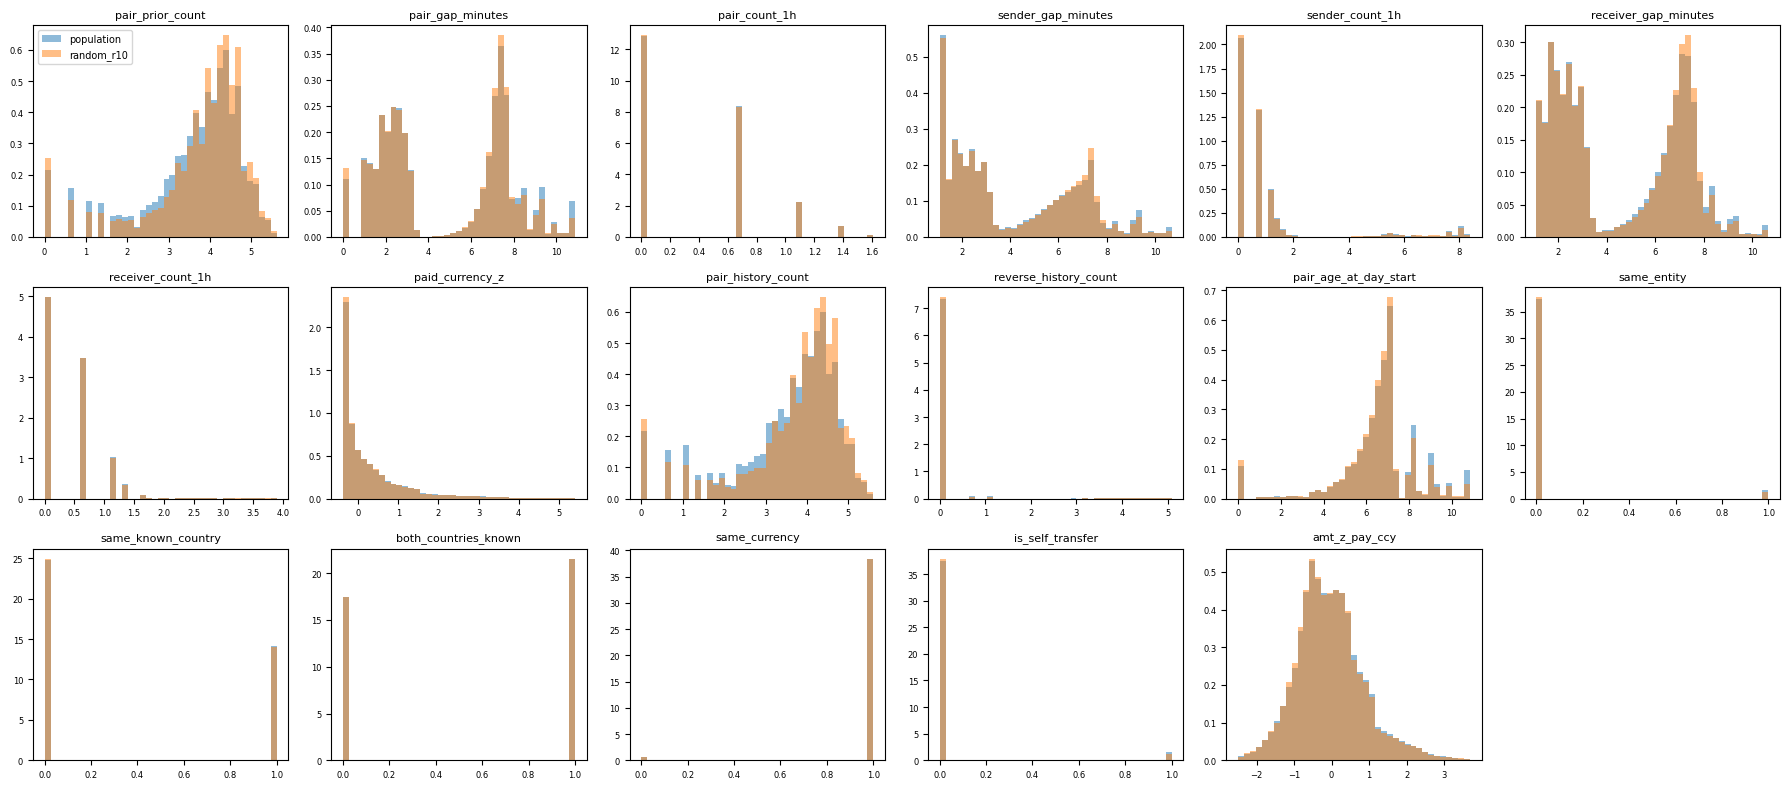

In [8]:
import matplotlib.pyplot as plt
name = f"random_r{R}"
feat_dir = L.features_dir("features")
sel = pd.read_parquet(L.SAMPLING / "select" / name / "selected.parquet"); smp = sel[sel.y == 0]
pop_ids = np.sort(np.random.default_rng(0).choice(lab[lab.y == 0].edge_id.to_numpy(), 300_000, replace=False))
Xp, Xs = audit.read_features(con, feat_dir, pop_ids), audit.read_features(con, feat_dir, np.sort(smp.edge_id.to_numpy()[np.random.default_rng(0).choice(len(smp), min(len(smp), 300_000), replace=False)]))
fig, axes = plt.subplots(3, 6, figsize=(18, 8))
for j, ax in enumerate(axes.ravel()[:17]):
    lo, hi = np.quantile(Xp[:, j], [0.001, 0.999]); bins = np.linspace(lo, hi, 40)
    ax.hist(Xp[:, j], bins, density=True, alpha=.5, label="population"); ax.hist(Xs[:, j], bins, density=True, alpha=.5, label=name)
    ax.set_title(L.EDGE_FEATURES[j], fontsize=8); ax.tick_params(labelsize=6)
axes.ravel()[0].legend(fontsize=7); axes.ravel()[17].axis("off"); fig.tight_layout(); plt.show()

## 3. 학습 (train)

처음 한 번은 `GraphStore` memmap 캐시(엣지 피처 1.8억×17 float32 ≈ 12GB + adjacency)를 만드느라 오래 걸린다. 그 다음부턴 바로.
`run.json` 있으면 건너뛴다 (다시 돌리려면 `runs/<run_name>/` 삭제). 아래 두 셀은 GRID 가 끝난 뒤 결과 확인용.

In [9]:
# 완료된 실험 조건 전부 — run.json 요약 + 에폭별 검증 AP
import glob
runs = {}
for f in sorted(glob.glob(str(L.SAMPLING / "runs" / "*" / "run.json"))):
    r = json.loads(open(f, encoding="utf-8").read())
    runs[r["run_name"]] = dict(select=r["select"], apply=r["apply"], reweight=r["reweight"], pi_eff=r["pi_eff"], seed=r["seed"], pos_weight=round(r["pos_weight"], 2),
                               train_rows=r["train_rows"], epochs=r["epochs_run"], best_epoch=r["best_epoch"],
                               ms_per_target=round(r["train_sec_per_epoch"] / r["train_rows"] * 1000, 2), sec_per_epoch=round(r["train_sec_per_epoch"]),
                               gpu_gb=(round(r["gpu_peak_gb"], 1) if r["gpu_peak_gb"] else None), **{k: round(v, 4) for k, v in r["val"].items()})
summary = pd.DataFrame(runs).T
print(f"완료 {len(runs)}개 조건")
display(summary)

hist = pd.concat([pd.read_csv(Path(f).parent / "history.csv").assign(run=Path(f).parent.name) for f in glob.glob(str(L.SAMPLING / "runs" / "*" / "run.json"))], ignore_index=True) if runs else None
hist.pivot(index="epoch", columns="run", values="AP").round(4) if runs else None


완료 1개 조건


,select,apply,reweight,pi_eff,seed,pos_weight,train_rows,epochs,best_epoch,ms_per_target,sec_per_epoch,gpu_gb,AP,F1,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE
random_r10_loss_none_pi0.25_s42,random_r10,loss,none,0.25,42,3.33,1037399,1,1,1.8,1866,2.2,0.067,0.1563,0.1084,0.2802,0.8119,0.5222,0.2833,0.0271


run,random_r10_loss_none_pi0.25_s42
epoch,
1,0.067


### 검증 점수 분포 — 완료된 조건 전부 (양성/정상 점수 히스토그램, F1 임계값)

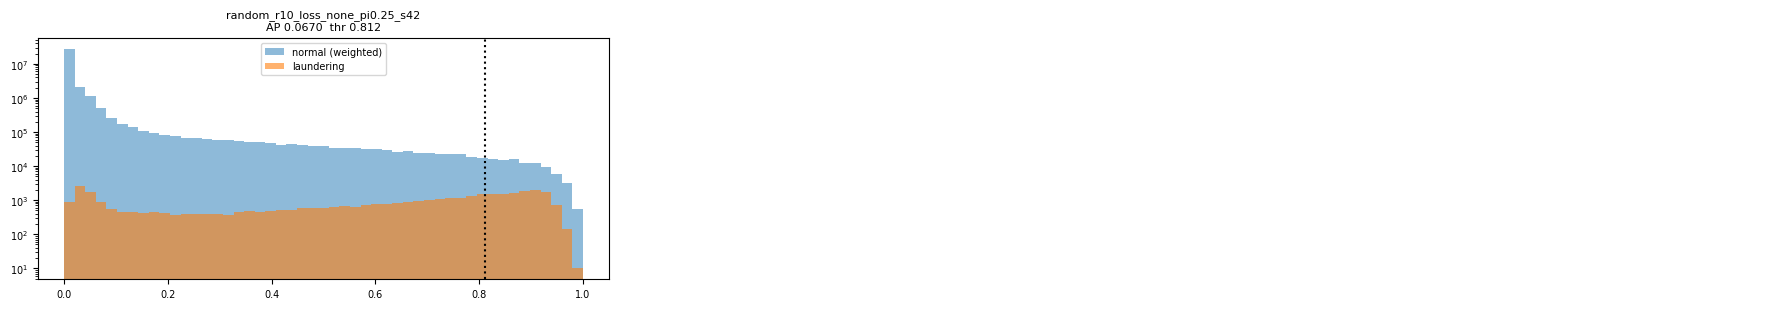

In [10]:
# 검증 점수 분포 — 조건별 양성/정상 히스토그램과 F1 임계값
names = list(runs); cols = 3; rows_ = max(1, -(-len(names) // cols))
fig, axes = plt.subplots(rows_, cols, figsize=(6 * cols, 3.2 * rows_), squeeze=False); bins = np.linspace(0, 1, 50)
for ax, name in zip(axes.ravel(), names):
    vs = pd.read_parquet(L.SAMPLING / "runs" / name / "val_scores.parquet")
    ax.hist(vs[vs.y == 0].score, bins, weights=vs[vs.y == 0].w, alpha=.5, label="normal (weighted)", log=True)
    ax.hist(vs[vs.y == 1].score, bins, alpha=.6, label="laundering", log=True)
    ax.axvline(runs[name]["threshold"], color="k", ls=":"); ax.set_title(f"{name}\nAP {runs[name]['AP']:.4f}  thr {runs[name]['threshold']:.3f}", fontsize=8); ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(names):]: ax.axis("off")
axes[0, 0].legend(fontsize=7); fig.tight_layout(); plt.show()


### 본 실험 — 단계별 조건 (주석을 풀며 실행)

```
1차  random × r{10,30,100} × none + r10 ipw 대조     4조건   ← 비율·가중치 축
2차  최적 r 에서 strata / hard / cssmc                 3~4조건 ← 방식 축 (select 셀 2차 블록 먼저)
3차  최적 (r, 방식) 에서 pi_eff {0.10, 0.50}           2조건
4차  최적에서 struct                                    1조건
5차  상위 2~3개 조건 시드 43, 44                        4~6조건
```
수 시간 단위라 터미널 `nohup` 권장. 노트북에서 돌릴 땐 브라우저를 닫아도 커널은 계속 돈다 (출력은 로그 파일이 안전).

In [11]:
# 실험 조건 = (select 이름, apply, reweight, pi_eff, seed). run.json 있으면 건너뜀 → 주석만 풀며 단계적으로 실행.
# 이름은 설정 셀의 R / BEST 로 조합되므로 단계가 바뀌어도 여기 값은 안 고친다.
# 속도 350 target/s 기준 1에폭: r10 50분 · r30 2.3h · r100 7.5h
GRID = [
    # ── 1차: 비율·가중치 축 ────────────────────────────────────────────
    ("random_r10",  "loss", "none", 0.25, 42),
    ("random_r10",  "loss", "ipw",  0.25, 42),      # 대조군 (태훈님 방식 = full 손실 불편추정)
    ("random_r30",  "loss", "none", 0.25, 42),
    ("random_r100", "loss", "none", 0.25, 42),      # 사실상 기준선 (none 대체)

    # ── 2차: 방식 축 (R 에서) ──────────────────────────────────────────
    # (f"strata_r{R}_day-amount-cross_bank",                 "loss", "none", 0.25, 42),
    # (f"strata_r{R}_day-amount-recent-cross_bank-new_pair", "loss", "none", 0.25, 42),
    # (f"hard_r{R}",                                         "loss", "none", 0.25, 42),
    # (f"cssmc_r{R}",                                        "loss", "none", 0.25, 42),

    # ── 3차: 양성 비중 축 (BEST 에서) ───────────────────────────────────
    # (BEST, "loss", "none", 0.10, 42),
    # (BEST, "loss", "none", 0.50, 42),

    # ── 4차: 구조 샘플링 대조 (BEST 에서) ──────────────────────────────
    # (BEST, "struct", "none", 0.25, 42),

    # ── 5차: 상위 조건 시드 반복 (BEST 와 2위 조건) ────────────────────
    # (BEST, "loss", "none", 0.25, 43),
    # (BEST, "loss", "none", 0.25, 44),
]
# 에폭은 상한 — 검증 AP 가 2에폭 연속 안 오르면(patience 2) 조기 종료. r100 만 시간 때문에 3.
EPOCHS = {"random_r100": "3"}
for s, ap_, rw, pi, seed in GRID:
    train.main(["--select", s, "--apply", ap_, "--reweight", rw, "--pi-eff", str(pi), "--seed", str(seed),
                "--val", VAL, "--epochs", EPOCHS.get(s, "6"), "--patience", "2", "--batch", "32", "--threads", str(THREADS), "--memory", MEMORY])


[06:12:42] 완료된 조건: random_r10_loss_none_pi0.25_s42
[06:12:42] random_r10_loss_ipw_pi0.25_s42: target 1,037,399 (양성 94,309, 정상 943,090), 정상 가중치 합 87,477,917, pos_weight=309.19
[06:12:42] GraphStore 캐시 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/cache/features
[06:14:12]   epoch 1 0/1,037,399 loss 1.0288
[06:15:55]   epoch 1 6,400/1,037,399 loss 0.3697
[06:16:15]   epoch 1 12,800/1,037,399 loss 0.2496
[06:16:33]   epoch 1 19,200/1,037,399 loss 0.1978
[06:16:52]   epoch 1 25,600/1,037,399 loss 0.2133
[06:17:11]   epoch 1 32,000/1,037,399 loss 0.1818
[06:17:30]   epoch 1 38,400/1,037,399 loss 0.1807
[06:17:48]   epoch 1 44,800/1,037,399 loss 0.1987
[06:18:07]   epoch 1 51,200/1,037,399 loss 0.1802
[06:18:26]   epoch 1 57,600/1,037,399 loss 0.1796
[06:18:44]   epoch 1 64,000/1,037,399 loss 0.1672
[06:19:03]   epoch 1 70,400/1,037,399 loss 0.1798
[06:19:22]   epoch 1 76,800/1,037,399 loss 0.1837
[06:19:41]   epoch 1 83,200/1,037,399 loss 0.1760
[06:19:59]   epoch 1 89,600/1,0

## 4. 합치기 (collect) — 통계 감사 + 모델 지표 한 표

=== 선택 결과 통계 감사 (학습 무관) ===
              kl_raw   kl_ipw  psi_raw  daily_keep_ratio  hour_jsd  hard_frac_sel  hard_frac_pop  struct_pos_hop1_keep
select                                                                                                                
none         0.00000  0.00000  0.00000           1.00000   0.00000        0.23056        0.23056               1.00000
random_r100  0.00387  0.00000  0.00760           5.36773   0.00008        0.23774        0.23601               0.11318
random_r10   0.00404  0.00001  0.00796           5.36773   0.00008        0.23262        0.23056               0.01548
random_r30   0.00385  0.00001  0.00756           5.36773   0.00008        0.23772        0.23601               0.03715

                                                    AP           recall_at_1pct     ECE train_sec_per_epoch
                                                  mean std count           mean    mean                mean
select      method ratio apply reweight p

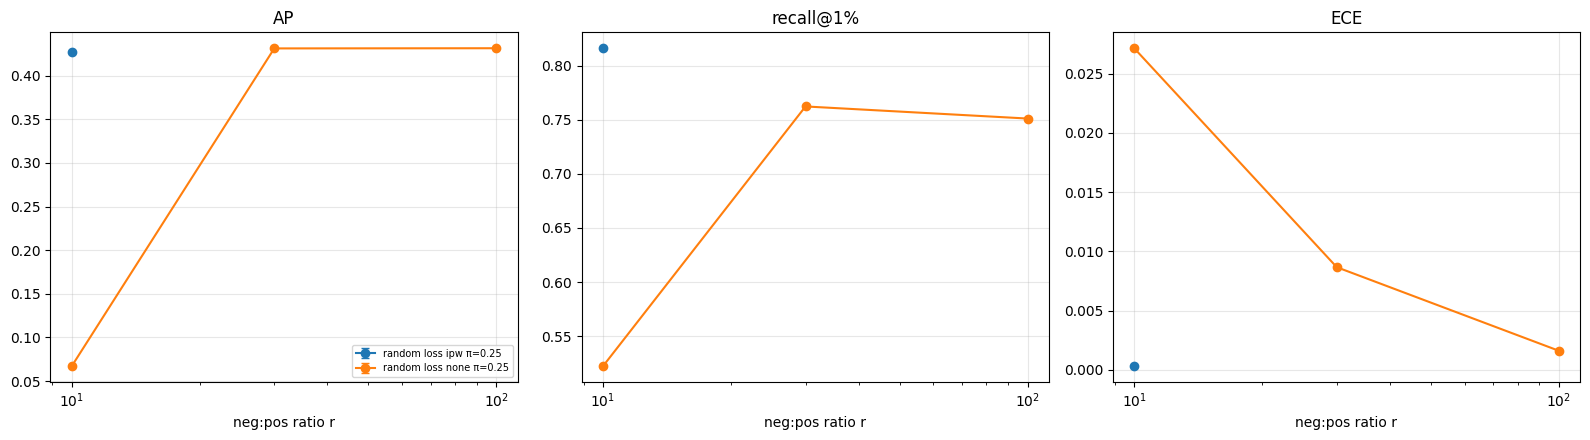

,run_name,method,ratio,apply,reweight,pi_eff,pos_weight,train_rows,AP,F1,recall_at_1pct,unmatched_recall_at_1pct,ECE,kl_raw,daily_keep_ratio,hard_frac_sel,train_sec_per_epoch,gpu_peak_gb
1,random_r10_loss_ipw_pi0.25_s42,random,10.0,loss,ipw,0.25,309.1890,1037399,0.4266,0.5038,0.8161,0.5635,0.0003,0.0040,5.3677,0.2326,4825.5000,2.1697
0,random_r10_loss_none_pi0.25_s42,random,10.0,loss,none,0.25,3.3333,1037399,0.0670,0.1563,0.5222,0.2833,0.0271,0.0040,5.3677,0.2326,1866.0000,2.1697
2,random_r30_loss_none_pi0.25_s42,random,30.0,loss,none,0.25,10.0000,3066892,0.4312,0.5052,0.7623,0.4480,0.0087,0.0039,5.3677,0.2377,10885.0000,2.1697
3,random_r100_loss_none_pi0.25_s42,random,100.0,loss,none,0.25,33.3333,9992132,0.4314,0.5163,0.7511,0.4673,0.0016,0.0039,5.3677,0.2377,32269.3333,2.1697


In [12]:
df, summ = collect.main()
df[["run_name", "method", "ratio", "apply", "reweight", "pi_eff", "pos_weight", "train_rows", "AP", "F1", "recall_at_1pct", "unmatched_recall_at_1pct", "ECE",
    "kl_raw", "daily_keep_ratio", "hard_frac_sel", "train_sec_per_epoch", "gpu_peak_gb"]].sort_values(["method", "ratio", "apply", "reweight"]).round(4) if df is not None else None


## 판단 기준 (메모)

1. audit 에서 `daily_keep_ratio` 가 수 배, `kl_raw` 가 random 보다 확 크면 학습 전에 탈락
2. `none`(샘플링 없음) 기준선 대비 AP 가 1 std 안에 드는 **가장 작은 r** — 비용이 목적
3. 같은 r·pi_eff 에서 cssmc/hard 가 random 을 이기는지 → 이기면 kl 또는 hard_frac 중 어느 쪽이 설명하는지
4. pi_eff 를 바꾼 조건은 ECE·threshold 도 같이 (확률이 밀림)
5. 시드 1개 결과에서 AP 차이 ±0.01 은 "차이 없음" (태훈님 시드 표준편차 0.005~0.016)